### 1. Problem Statement and Dataset Understanding.

# Credit Card Fraud Detection

## 1. Problem Statement and Dataset Understanding

The goal of this project is to identify potentially fraudulent credit card transactions using machine learning.

The dataset contains transaction information, anonymized features, transaction amounts, and a target column called `Class`.

- `Class = 0`: Legitimate transaction
- `Class = 1`: Fraudulent transaction

A major challenge is class imbalance: fraudulent transactions make up only a tiny fraction of the dataset. Therefore, accuracy alone will not be enough to evaluate our models.

In [8]:
import pandas as pd

df = pd.read_csv("creditcard.csv")
df.shape

(284807, 31)

### 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset's structure, features, and potential data-quality issues before building a machine learning model.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [9]:
df["Class"].value_counts(normalize=True).mul(100).round(4)

Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

In [6]:
df.isnull().sum().sum()

np.int64(0)

Matplotlib is building the font cache; this may take a moment.


<Axes: title={'center': 'Legitimate vs Fraudulent Transactions'}, xlabel='Class (0 = Legitimate, 1 = Fraud)', ylabel='Number of Transactions'>

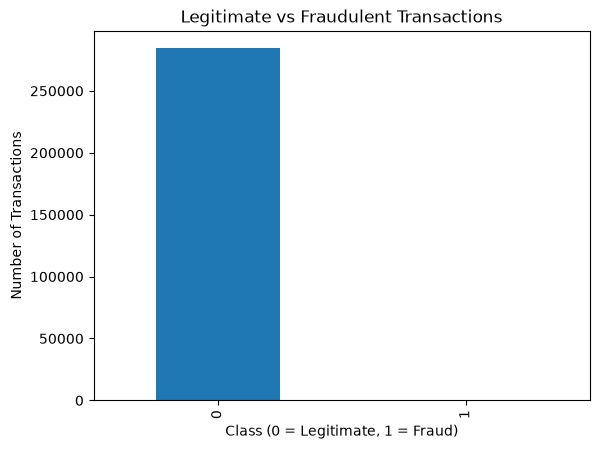

In [7]:
df["Class"].value_counts().plot(
    kind="bar",
    title="Legitimate vs Fraudulent Transactions",
    xlabel="Class (0 = Legitimate, 1 = Fraud)",
    ylabel="Number of Transactions"
)

#### 2.1 Summary Statistics

Examine the distributions of numerical features, including transaction amounts, to identify unusual values and understand the scale of the data.

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


#### 2.2 Data Quality

Check for missing values, duplicate rows, and unexpected target labels before preparing the data for modeling.

In [11]:
# Missing values in each column
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

# Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Duplicate rows
print("Total duplicate rows:", df.duplicated().sum())

# Target labels and their counts
print("\nTarget labels:")
print(df["Class"].value_counts().sort_index())

Missing values per column:
Time    0
V1      0
V2      0
V3      0
V4      0
V5      0
V6      0
V7      0
V8      0
V9      0
dtype: int64

Total missing values: 0
Total duplicate rows: 1081

Target labels:
Class
0    284315
1       492
Name: count, dtype: int64


#### 2.3 Transaction Amount Analysis

Examine transaction amounts for legitimate and fraudulent transactions to see whether their distributions differ.

In [12]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


#### 2.4 Visual Exploration

Visualize the class imbalance and compare transaction amount distributions. These plots help reveal patterns that summary tables may hide.

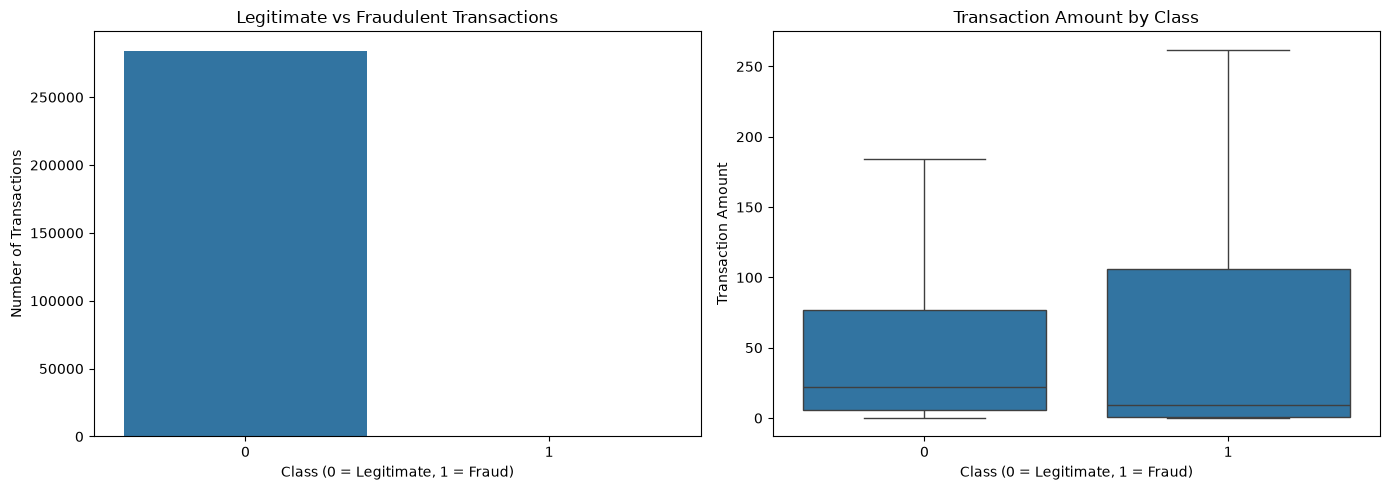

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Transaction class distribution
sns.countplot(data=df, x="Class", ax=axes[0])
axes[0].set_title("Legitimate vs Fraudulent Transactions")
axes[0].set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
axes[0].set_ylabel("Number of Transactions")

# Amount distributions, excluding extreme visual compression
sns.boxplot(data=df, x="Class", y="Amount", showfliers=False, ax=axes[1])
axes[1].set_title("Transaction Amount by Class")
axes[1].set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
axes[1].set_ylabel("Transaction Amount")

plt.tight_layout()
plt.show()

### 3. Data Preparation

In this stage, we will:
1. Investigate duplicate records.
2. Remove exact duplicates for our initial experiment.
3. Separate the input features (X) from the target (y).
4. Split the data into training and testing sets while preserving the fraud ratio.

In [18]:
from sklearn.model_selection import train_test_split

# 1. Investigate duplicate rows
print("Duplicate rows:", df.duplicated().sum())

duplicate_rows = df[df.duplicated(keep=False)]

print("\nClass distribution among rows involved in duplicates:")
print(duplicate_rows["Class"].value_counts())

# 2. Remove exact duplicate rows for this experiment
df_clean = df.drop_duplicates().copy()

print("\nOriginal shape:", df.shape)
print("Shape after removing duplicates:", df_clean.shape)

# 3. Separate features and target
X = df_clean.drop(columns="Class")
y = df_clean["Class"]

# 4. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Verify the split
print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

print("\nFraud percentage in training set:",
      round(y_train.mean() * 100, 4), "%")

print("Fraud percentage in testing set:",
      round(y_test.mean() * 100, 4), "%")

Duplicate rows: 1081

Class distribution among rows involved in duplicates:
Class
0    1822
1      32
Name: count, dtype: int64

Original shape: (284807, 31)
Shape after removing duplicates: (283726, 31)

Training features: (226980, 30)
Testing features: (56746, 30)

Training class counts:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class counts:
Class
0    56651
1       95
Name: count, dtype: int64

Fraud percentage in training set: 0.1665 %
Fraud percentage in testing set: 0.1674 %


### 4. Baseline Model — Logistic Regression

We will train a Logistic Regression classifier as our baseline.

Because fraudulent transactions are rare, we will use balanced class weights. We will also standardize the features so that variables with different scales do not disproportionately influence the model.

All preprocessing will be fitted using training data only.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build the preprocessing and modeling pipeline
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train using training data only
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully.")

Baseline Logistic Regression model trained successfully.


#### 4.1 Model Evaluation

We will evaluate our model on the held-out test set using precision, recall, F1-score, and a confusion matrix.

These metrics help us understand how well the model detects fraud and how many legitimate transactions it incorrectly flags.

Classification Report:

              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

Average Precision (PR-AUC summary): 0.6719
Confusion Matrix:
[[55262  1389]
 [   12    83]]


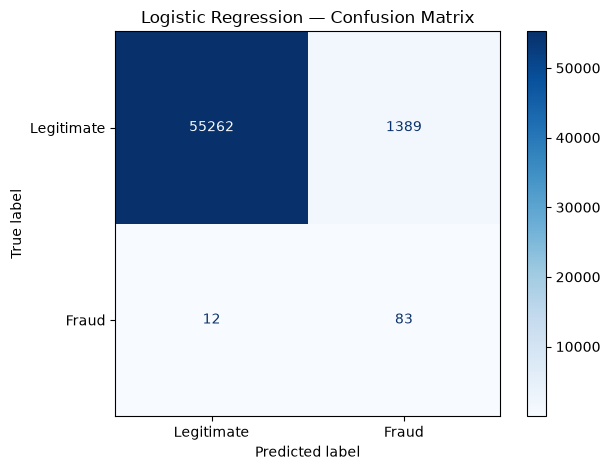

In [21]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    average_precision_score
)
import matplotlib.pyplot as plt

# Predict fraud labels for the test set
y_pred = baseline_model.predict(X_test)

# Get fraud probabilities for ranking-based evaluation
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# Print evaluation metrics
print("Classification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Average Precision (PR-AUC summary):",
      round(average_precision_score(y_test, y_prob), 4))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

In [22]:
tn, fp, fn, tp = cm.ravel()

print(f"True Negatives (TN):  {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP):  {tp}")

True Negatives (TN):  55262
False Positives (FP): 1389
False Negatives (FN): 12
True Positives (TP):  83


In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, y_threshold_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_threshold_pred, zero_division=0),
        "Fraud Alerts": int(y_threshold_pred.sum())
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1-score,Fraud Alerts
0,0.1,0.009,0.937,0.017,10251
1,0.2,0.017,0.916,0.033,5203
2,0.3,0.027,0.874,0.052,3102
3,0.4,0.040,0.874,0.076,2076
4,0.5,0.056,0.874,0.106,1472
5,0.6,0.079,0.874,0.145,1053
6,0.7,0.116,0.874,0.204,717
7,0.8,0.160,0.842,0.269,499
8,0.9,0.262,0.832,0.399,301


### 5. Model Comparison — Random Forest

We will train a Random Forest classifier and compare it with Logistic Regression using the same training and test split.

We will examine precision, recall, F1-score, and Average Precision rather than relying on accuracy alone.

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Classification Report:\n")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print(
    "Random Forest Average Precision:",
    round(average_precision_score(y_test, rf_prob), 4)
)

Random Forest Classification Report:

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.95      0.73      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Random Forest Average Precision: 0.8012


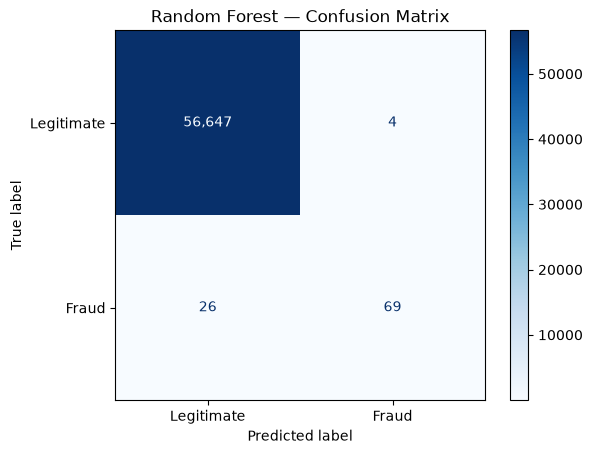

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format=","
)

plt.title("Random Forest — Confusion Matrix")
plt.show()

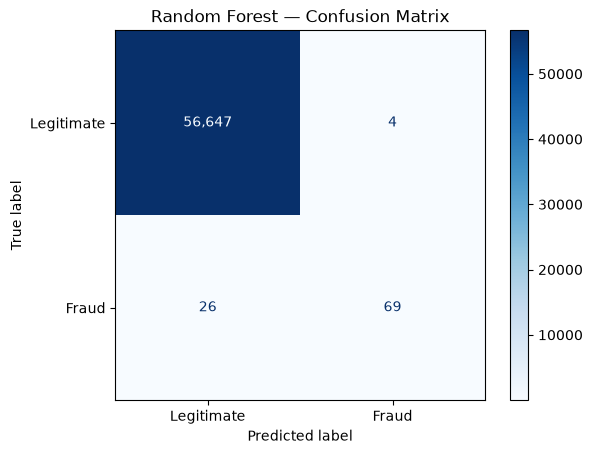

True Negatives (TN):  56,647
False Positives (FP): 4
False Negatives (FN): 26
True Positives (TP):  69


In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate the confusion matrix
cm = confusion_matrix(y_test, rf_pred)

# Display it
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot(cmap="Blues", values_format=",")
plt.title("Random Forest — Confusion Matrix")
plt.show()

# Print the individual counts
tn, fp, fn, tp = cm.ravel()

print(f"True Negatives (TN):  {tn:,}")
print(f"False Positives (FP): {fp:,}")
print(f"False Negatives (FN): {fn:,}")
print(f"True Positives (TP):  {tp:,}")

In [27]:
from sklearn.model_selection import train_test_split

# Split the training data into a smaller training set and a validation set
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training set:", X_train_final.shape)
print("Validation set:", X_val.shape)
print("Untouched test set:", X_test.shape)

print("\nFraud cases:")
print("Training:", int(y_train_final.sum()))
print("Validation:", int(y_val.sum()))
print("Test:", int(y_test.sum()))

Training set: (181584, 30)
Validation set: (45396, 30)
Untouched test set: (56746, 30)

Fraud cases:
Training: 302
Validation: 76
Test: 95


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Train using only the training set
rf_tuned = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train_final, y_train_final)

# Predict fraud probabilities on the validation set
y_val_prob = rf_tuned.predict_proba(X_val)[:, 1]

# Compare different thresholds
threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Fraud Alerts": int(y_val_pred.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Threshold,Precision,Recall,F1-score,Fraud Alerts
0,0.1,0.677,0.882,0.766,99
1,0.2,0.846,0.868,0.857,78
2,0.3,0.903,0.855,0.878,72
3,0.4,0.956,0.855,0.903,68
4,0.5,0.956,0.855,0.903,68
5,0.6,0.955,0.829,0.887,66
6,0.7,0.967,0.776,0.861,61
7,0.8,0.982,0.711,0.824,55
8,0.9,1.000,0.618,0.764,47


Decision threshold: 0.4

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.92      0.74      0.82        95

    accuracy                           1.00     56746
   macro avg       0.96      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Average Precision: 0.8115


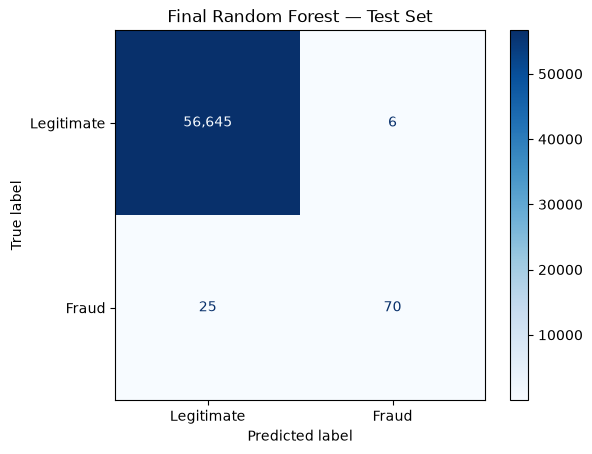

True Negatives:  56,645
False Positives: 6
False Negatives: 25
True Positives:  70


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Combine training and validation data
import pandas as pd

X_train_full = pd.concat([X_train_final, X_val])
y_train_full = pd.concat([y_train_final, y_val])

# Train the final model
final_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train_full, y_train_full)

# Evaluate on the untouched test set
final_threshold = 0.4

y_test_prob = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= final_threshold).astype(int)

print(f"Decision threshold: {final_threshold}\n")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print(
    "Average Precision:",
    round(average_precision_score(y_test, y_test_prob), 4)
)

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot(cmap="Blues", values_format=",")

plt.title("Final Random Forest — Test Set")
plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"True Negatives:  {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives:  {tp:,}")

In [30]:
# Select one legitimate transaction
legitimate = df_clean[df_clean["Class"] == 0].iloc[[0]]

# Select one fraudulent transaction
fraudulent = df_clean[df_clean["Class"] == 1].iloc[[0]]

print("Legitimate transaction:")
display(legitimate)

print("Fraudulent transaction:")
display(fraudulent)

Legitimate transaction:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0


Fraudulent transaction:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
541,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,...,0.517232,-0.035049,-0.465211,0.320198,0.044519,0.17784,0.261145,-0.143276,0.0,1


In [34]:
# Find the first fraudulent transaction's row index
fraud_index = df_clean.index[df_clean["Class"] == 1][0]

print("Try this row number in predict.py:", fraud_index)

Try this row number in predict.py: 541


In [35]:
# Find actual fraudulent transaction row numbers
fraud_indices = df_clean.index[df_clean["Class"] == 1]

print("First 10 fraudulent row numbers:")
print(fraud_indices[:10].tolist())

First 10 fraudulent row numbers:
[541, 623, 4920, 6108, 6329, 6331, 6334, 6336, 6338, 6427]


In [36]:
# Match predict.py's dataset cleaning and row numbering
df_for_prediction = (
    pd.read_csv("creditcard.csv")
    .drop_duplicates()
    .reset_index(drop=True)
)

# Find the first confirmed fraud row
fraud_index = df_for_prediction.index[
    df_for_prediction["Class"] == 1
][0]

print("Correct row number for predict.py:", fraud_index)
print("Actual class:", df_for_prediction.loc[fraud_index, "Class"])

Correct row number for predict.py: 534
Actual class: 1
